In [5]:
import geopandas as gpd
import matplotlib.pyplot as plt
import momepy as mp
import networkx as nx

In [60]:
gdf = gpd.read_file("../data/processed/bikenet_wpop_edges.gpkg")

In [61]:
def buffer_graph(G_current, G_full, buffer=500):
    """
    Buffer a subgraph G_current of the graph G_full by adding to it any node and edges within a network distance of the buffer.
    """
    contact_nodes = find_contact_nodes(G_current, G_full)
    return G_full.edge_subgraph(
        {
            edge
            for edge_arr in [
                nx.ego_graph(G_full, n, radius=buffer, distance="length").edges
                for n in contact_nodes
            ]
            + [G_current.edges]
            for edge in edge_arr
        }
    )


def find_contact_nodes(G_current, G_full):
    """
    Find nodes that have both edges built and not built.
    """
    return [
        node
        for node in G_current.nodes
        if len(G_full.edges(node)) > len(G_current.edges(node))
    ]

In [62]:
G = mp.gdf_to_nx(gdf)

In [63]:
G_built = G.edge_subgraph(
    [edge for edge in G.edges if G.edges[edge]["built_in"] == "2021-01-01"]
)

In [64]:
G_buffered = buffer_graph(G_built, G, buffer=400)

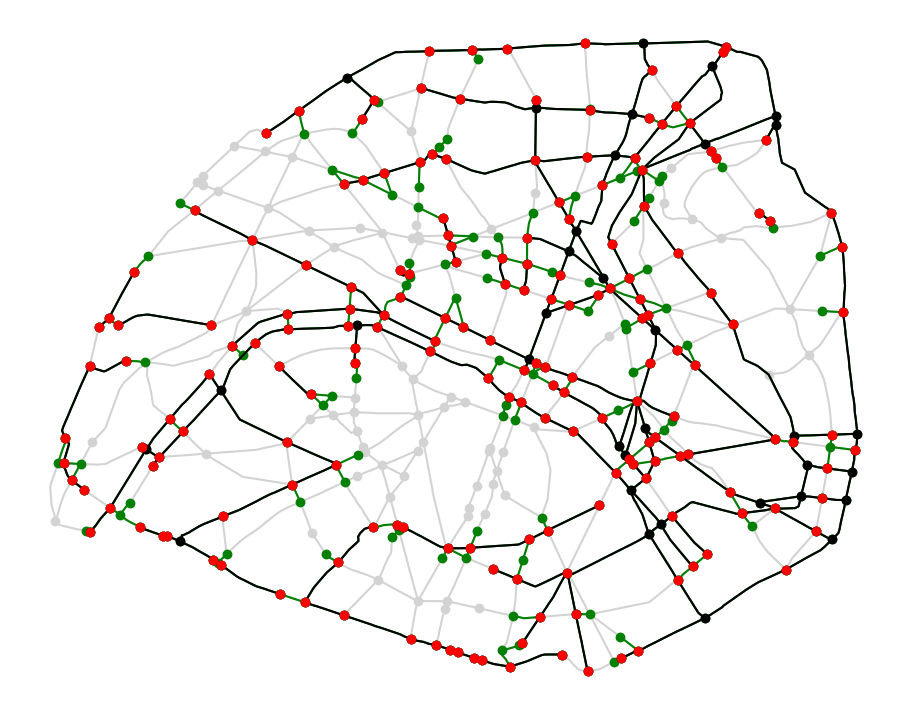

In [57]:
fig, ax = plt.subplots(figsize=(16, 9))
ax.axis("off")
gdf_nodes, gdf_edges = mp.nx_to_gdf(G_built, points=True, lines=True)
gdf_nodes.plot(ax=ax, color="black", zorder=4)
gdf_edges.plot(ax=ax, color="black", zorder=4)
gdf_nodes.to_file("../notebooks/n_built.gpkg")
gdf_edges.to_file("../notebooks/e_built.gpkg")
gdf_nodes, gdf_edges = mp.nx_to_gdf(G_buffered, points=True, lines=True)
gdf_nodes.plot(ax=ax, color="green", zorder=3)
gdf_edges.plot(ax=ax, color="green", zorder=3)
gdf_nodes.to_file("../notebooks/n_buff.gpkg")
gdf_edges.to_file("../notebooks/e_buff.gpkg")
gdf_nodes, gdf_edges = mp.nx_to_gdf(G, points=True, lines=True)
gdf_nodes.plot(ax=ax, color="lightgrey", zorder=2)
gdf_edges.plot(ax=ax, color="lightgrey", zorder=2)
gdf_nodes.to_file("../notebooks/n_full.gpkg")
gdf_edges.to_file("../notebooks/e_full.gpkg")
contact_nodes = find_contact_nodes(G_built, G)
gdf_nodes["id"] = gdf_nodes.apply(lambda df: (df.x, df.y), axis=1)
gdf_contact = gdf_nodes[gdf_nodes["id"].isin(contact_nodes)]
gdf_contact.plot(ax=ax, color="red", zorder=5)
gdf_contact.to_file("../notebooks/n_contact.gpkg")

In [79]:
"""Plot the lineplot of number of components for the real order and all random strategies."""

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BUFFER_SIZE = 400
NUM_TRIAL = 1000
PARAMS_DICT = {
    "order": [
        "coverage",
        "directness",
        "dual_betweenness",
        "road_hierarchy_coverage",
        "road_hierarchy_directness",
        "real_random",
        "random",
        "random_disconnected",
    ],
    "label": [
        "Coverage",
        "Directness",
        "Dual betweenness",
        "Hierarchy-coverage",
        "Hierarchy-directness",
        "Empirical",
        "Random",
        "Random-disconnected",
    ],
    "color": [
        "#0173b2",
        "#d55e00",
        "#017856",
        "#46afe8",
        "#ea914d",
        "#B0B0B0",
        "#949494",
        "pink",
    ],
    "figsize": [11.69, 8.27],
    "rcparams": {
        "font.size": 10,
        "font.family": "sans-serif",
        "font.sans-serif": "Arial",
        "axes.grid": "False",
        "axes.spines.right": "False",
        "axes.spines.top": "False",
        "axes.axisbelow": "True",
        "grid.color": "E1E1E1",
        "xtick.bottom": "True",
        "ytick.left": "True",
        "figure.frameon": "False",
        "figure.dpi": 300,
        "savefig.bbox": "tight",
        "legend.edgecolor": "black",
        "legend.facecolor": "F7F7F7",
    },
}
FOLDEROOT = "../data/processed/"

In [80]:
gdf_edges["pop"].sum()

np.float64(974393.1078478515)

In [81]:
gdf[gdf["length"] > 400]["pop"].sum() / gdf["pop"].sum()

np.float64(0.8611956105379496)

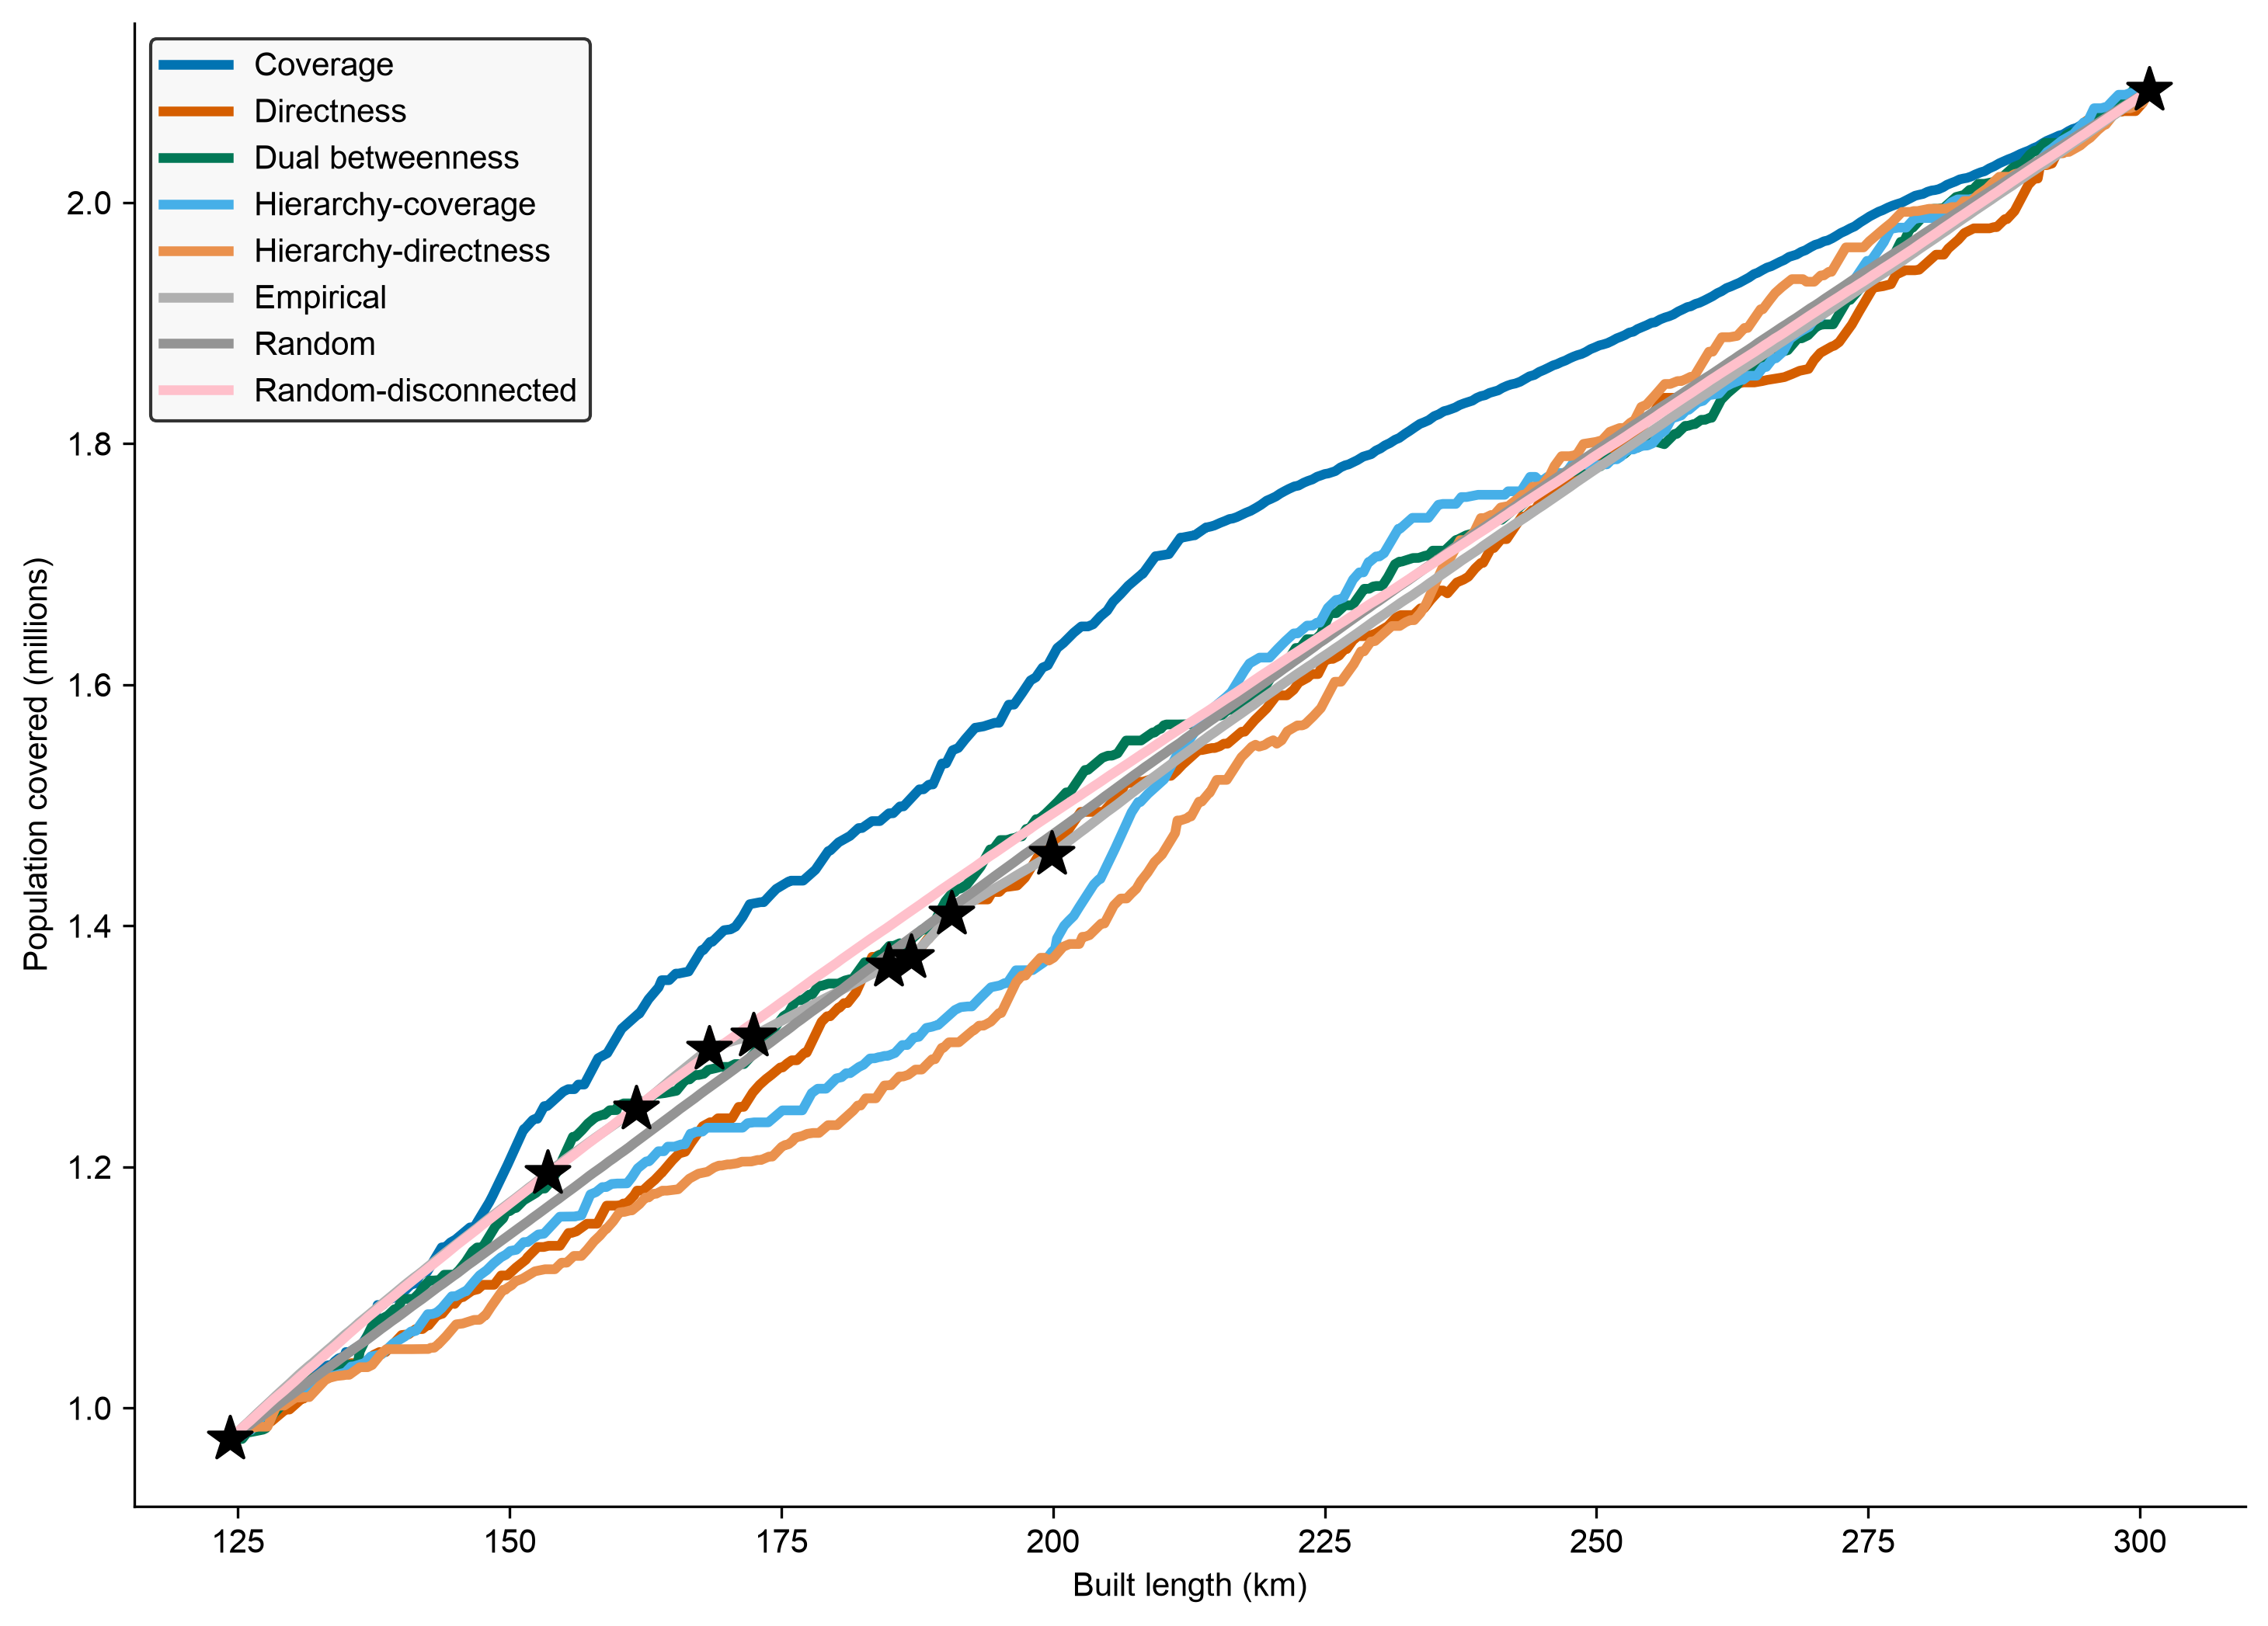

In [82]:
for key in PARAMS_DICT["rcparams"]:
    mpl.rcParams[key] = PARAMS_DICT["rcparams"][key]
fig, ax = plt.subplots(figsize=PARAMS_DICT["figsize"])
df = pd.read_json(FOLDEROOT + f"2021/bs_{BUFFER_SIZE}_real/metrics_growth.json")
ax.scatter(
    df["xx"].values / 10**3,
    df["pop_buff"].values / 10**6,
    color="black",
    marker="*",
    s=200,
    zorder=3,
)
for met, metname, color in zip(
    PARAMS_DICT["order"], PARAMS_DICT["label"], PARAMS_DICT["color"]
):
    if met in [
        "real_random",
        "random",
        "random_disconnected",
        "random_relaxed",
    ]:
        pop = []
        xx = []
        for i in range(NUM_TRIAL):
            df = pd.read_json(
                FOLDEROOT
                + f"2021/bs_{BUFFER_SIZE}_{met}/{met}_{i:03}/metrics_growth.json"
            )
            pop.append(df["pop_buff"].values)
            xx.append(df["xx"].values)
        pop = np.mean(np.transpose(pop), axis=1)
        xx = np.mean(np.transpose(xx), axis=1)
        ax.plot(xx / 10**3, pop / 10**6, color=color, label=metname, linewidth=3)
    elif met == "coverage":
        pop = []
        xx = []
        for i in range(20):
            df = pd.read_json(
                FOLDEROOT
                + f"2021/bs_{BUFFER_SIZE}_{met}/{met}_{i:03}/metrics_growth.json"
            )
            pop.append(df["pop_buff"].values)
            xx.append(df["xx"].values)
        pop = np.mean(np.transpose(pop), axis=1)
        xx = np.mean(np.transpose(xx), axis=1)
        ax.plot(xx / 10**3, pop / 10**6, color=color, label=metname, linewidth=3)
    else:
        df = pd.read_json(
            FOLDEROOT + f"2021/bs_{BUFFER_SIZE}_{met}/metrics_growth.json"
        )
        ax.plot(
            df["xx"] / 10**3,
            df["pop_buff"] / 10**6,
            color=color,
            label=metname,
            linewidth=3,
        )
ax.set_xlabel("Built length (km)")
ax.set_ylabel("Population covered (millions)")
ax.legend()